# RQ2 — ST-GNN on redacted call-path topologies vs. a log-dependent baseline

**Question:** Can a Spatio-Temporal Graph Neural Network (ST-GNN), trained only on redacted call-path topology and time-weighted edge latencies (no service/operation text), reach detection accuracy comparable to a log-dependent baseline for application-layer lateral movement?

**Data:** `raw_traces 2/run_01` … `run_09` (Jaeger/OpenTelemetry spans) paired with real, ground-truth per-trace labels from `ShadowTrace_csv/run_01.csv` … `run_09.csv` (columns: `trace_id, run_id, label, span_count, start_time, duration`). Every `trace_id` in each CSV has a matching `trace_<id>.json` file — verified 1:1 across all 9 runs, 502,029 traces total. This supersedes the earlier heuristic/proxy labeling — labels now come directly from ShadowTrace's own ground truth, not from detecting an injected service name ourselves.

**Label balance:** ~33% positive (`label == 1` = lateral movement) in every run, so the dataset is properly balanced rather than a rare-event problem — no heavy class weighting is needed.

**Redaction boundary (unchanged):** the ST-GNN only ever sees structural features (DAG depth, in/out-degree, normalized subtree size, root/leaf flags) and relative timing (z-scored log start-offset, z-scored log edge latency) — no service or operation identity. The log-dependent baseline is deliberately given the raw `service:operation` text per trace, which is what makes it "log-dependent." The CSV label itself is the ground truth for both models; it is never a model input.

In [1]:
# !pip install torch torch_geometric networkx scikit-learn pandas matplotlib

In [2]:
import csv
import json
import random
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
RAW_DIR = Path("raw_traces 2")
CSV_DIR = Path("ShadowTrace_csv")
RUN_IDS = [f"run_{i:02d}" for i in range(1, 10)]
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical palette slots 1 & 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. Parse raw traces into call-path DAGs

In [4]:
def parse_trace_file(path):
    with open(path, "r") as f:
        return json.load(f)


def build_call_graph(trace):
    """One NetworkX DiGraph per trace: nodes = spans, edges = CHILD_OF parent->child."""
    processes = {pid: p["serviceName"] for pid, p in trace.get("processes", {}).items()}
    spans = trace.get("spans", [])
    span_by_id = {s["spanID"]: s for s in spans}

    g = nx.DiGraph()
    for s in spans:
        g.add_node(
            s["spanID"],
            service=processes.get(s["processID"], "unknown"),
            operation=s.get("operationName", ""),
            start_time=s.get("startTime", 0),
            duration=max(s.get("duration", 0) or 0, 0),
        )
    for s in spans:
        for ref in s.get("references", []):
            if ref.get("refType") == "CHILD_OF" and ref["spanID"] in span_by_id:
                g.add_edge(ref["spanID"], s["spanID"])
    return g


def load_labels(csv_path):
    """trace_id -> ground-truth label (0 = benign, 1 = lateral_movement), from ShadowTrace_csv."""
    with open(csv_path, newline="") as f:
        return {row["trace_id"]: int(row["label"]) for row in csv.DictReader(f)}


def log_tokens(g):
    """Raw log-text representation of a trace, used ONLY by the log-dependent baseline."""
    return " ".join(f"{d['service']}:{d['operation']}".replace(" ", "_") for _, d in g.nodes(data=True))


def extract_raw_features(g):
    # Redacted structural features (no service/operation identity) + raw timing values.
    # Timing values are left un-normalized here; corpus-wide z-scoring happens once, after
    # every trace has been visited, so we never re-open the raw graphs a second time.
    nodes = list(g.nodes())
    idx = {n: i for i, n in enumerate(nodes)}
    times = [g.nodes[n]["start_time"] for n in nodes]
    t0 = min(times) if times else 0

    # BFS depth from all roots (in-degree 0), forest-safe
    roots = [n for n in nodes if g.in_degree(n) == 0]
    depth = {}
    frontier = [(r, 0) for r in roots]
    seen = set(roots)
    while frontier:
        node, d = frontier.pop(0)
        depth[node] = d
        for succ in g.successors(node):
            if succ not in seen:
                seen.add(succ)
                frontier.append((succ, d + 1))
    for n in nodes:
        depth.setdefault(n, 0)
    max_depth = max(depth.values()) or 1
    n_nodes = len(nodes)

    node_struct, raw_duration, raw_offset = [], [], []
    for n in nodes:
        d = g.nodes[n]
        in_deg, out_deg = g.in_degree(n), g.out_degree(n)
        subtree = len(nx.descendants(g, n))
        node_struct.append(
            [depth[n] / max_depth, float(in_deg), float(out_deg), subtree / n_nodes, float(in_deg == 0), float(out_deg == 0)]
        )
        raw_duration.append(d["duration"])
        raw_offset.append(max(d["start_time"] - t0, 0))

    edges = list(g.edges())
    edge_index = [[idx[u] for u, v in edges], [idx[v] for u, v in edges]]
    raw_latency = [max(g.nodes[v]["start_time"] - g.nodes[u]["start_time"], 0) for u, v in edges]

    return {
        "node_struct": node_struct,
        "raw_duration": raw_duration,
        "raw_offset": raw_offset,
        "edge_index": edge_index,
        "raw_latency": raw_latency,
    }

In [5]:
records = []
all_durations, all_offsets, all_latencies = [], [], []

for run_id in RUN_IDS:
    label_map = load_labels(CSV_DIR / f"{run_id}.csv")
    trace_files = sorted((RAW_DIR / run_id).glob("trace_*.json"))
    run_pos, run_used = 0, 0
    for fp in trace_files:
        trace_id = fp.stem[len("trace_"):]
        if trace_id not in label_map:
            continue
        try:
            trace = parse_trace_file(fp)
            g = build_call_graph(trace)
            if g.number_of_nodes() == 0:
                continue
            feats = extract_raw_features(g)
            tokens = log_tokens(g)
            label = label_map[trace_id]
        except Exception as e:
            print(f"Skipping {fp.name}: {e}")
            continue

        run_pos += label
        run_used += 1
        all_durations.extend(feats["raw_duration"])
        all_offsets.extend(feats["raw_offset"])
        all_latencies.extend(feats["raw_latency"])
        records.append({"file": fp.name, "run": run_id, "label": label, "tokens": tokens, "features": feats})

    print(f"{run_id}: {run_used} traces, {run_pos} positive ({run_pos / run_used * 100:.1f}%)")

labels = np.array([r["label"] for r in records])
print(f"\nParsed {len(records)} valid traces from {len(RUN_IDS)} runs (ShadowTrace ground truth)")
print(
    f"Class balance -> benign: {(labels == 0).sum()}, "
    f"lateral_movement: {(labels == 1).sum()} "
    f"({labels.mean() * 100:.2f}% positive)"
)

run_01: 51542 traces, 16086 positive (31.2%)


run_02: 55391 traces, 17731 positive (32.0%)


run_03: 55150 traces, 18439 positive (33.4%)


run_04: 57155 traces, 18823 positive (32.9%)


run_05: 55942 traces, 18822 positive (33.6%)


run_06: 57353 traces, 19242 positive (33.6%)


run_07: 54000 traces, 17737 positive (32.8%)


run_08: 60401 traces, 20367 positive (33.7%)


run_09: 55095 traces, 18049 positive (32.8%)



Parsed 502029 valid traces from 9 runs (ShadowTrace ground truth)
Class balance -> benign: 336733, lateral_movement: 165296 (32.93% positive)


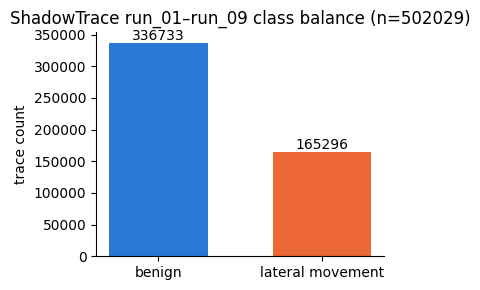

In [6]:
counts = [int((labels == 0).sum()), int((labels == 1).sum())]

fig, ax = plt.subplots(figsize=(4, 3))
bars = ax.bar(["benign", "lateral movement"], counts, color=[BLUE, ORANGE], width=0.6)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{c}", ha="center", va="bottom")
ax.set_ylabel("trace count")
ax.set_title(f"ShadowTrace run_01–run_09 class balance (n={len(labels)})")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Corpus-wide normalization stats, then redact identity into structural + time-weighted features

Node features: normalized DAG depth, in/out-degree, normalized subtree size, root/leaf flags, z-scored log-duration, z-scored log-start-offset (relative to the trace's own start — never absolute wall-clock time, so it can't leak the label).

Edge features: z-scored log latency = `child.startTime - parent.startTime` (the "time-weighted edge latency" from RQ2). All raw values were already collected once during ingestion above, so this pass only computes mean/std and rebuilds the small precomputed arrays into tensors — no re-parsing of the 502K raw trace files.

In [7]:
# all_durations / all_offsets / all_latencies were already accumulated during ingestion above
# (one pass over the raw traces only) - this cell just turns them into normalization stats.
if not all_latencies:
    all_latencies = [0]

log_durations = np.log1p(all_durations)
log_offsets = np.log1p(all_offsets)
log_latencies = np.log1p(all_latencies)

DUR_MEAN, DUR_STD = log_durations.mean(), log_durations.std() + 1e-6
OFF_MEAN, OFF_STD = log_offsets.mean(), log_offsets.std() + 1e-6
LAT_MEAN, LAT_STD = log_latencies.mean(), log_latencies.std() + 1e-6

print(f"duration: mean={DUR_MEAN:.3f} std={DUR_STD:.3f}")
print(f"offset:   mean={OFF_MEAN:.3f} std={OFF_STD:.3f}")
print(f"latency:  mean={LAT_MEAN:.3f} std={LAT_STD:.3f}")

duration: mean=5.666 std=1.955
offset:   mean=8.132 std=2.452
latency:  mean=7.323 std=2.085


In [8]:
def build_pyg(record):
    feats = record["features"]
    node_struct = feats["node_struct"]

    dur_z = (np.log1p(feats["raw_duration"]) - DUR_MEAN) / DUR_STD
    off_z = (np.log1p(feats["raw_offset"]) - OFF_MEAN) / OFF_STD
    x = torch.tensor(
        [ns + [dz, oz] for ns, dz, oz in zip(node_struct, dur_z.tolist(), off_z.tolist())],
        dtype=torch.float,
    )

    edge_index_raw = feats["edge_index"]
    if edge_index_raw[0]:
        edge_index = torch.tensor(edge_index_raw, dtype=torch.long)
        lat_z = (np.log1p(feats["raw_latency"]) - LAT_MEAN) / LAT_STD
        edge_attr = torch.tensor(lat_z, dtype=torch.float).unsqueeze(1)
    else:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr = torch.zeros((0, 1), dtype=torch.float)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=torch.tensor([record["label"]], dtype=torch.float))


NODE_DIM = 8
dataset = [build_pyg(r) for r in records]
print(f"Built {len(dataset)} PyG graphs, node feature dim = {NODE_DIM}")

Built 502029 PyG graphs, node feature dim = 8


## 3. Stratified train / val / test split (shared indices across ST-GNN and baseline)

In [9]:
indices = np.arange(len(records))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.3, stratify=labels, random_state=RANDOM_SEED
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=labels[temp_idx], random_state=RANDOM_SEED
)

train_set = [dataset[i] for i in train_idx]
val_set = [dataset[i] for i in val_idx]
test_set = [dataset[i] for i in test_idx]

print(f"train={len(train_set)} (pos={labels[train_idx].sum()})")
print(f"val={len(val_set)} (pos={labels[val_idx].sum()})")
print(f"test={len(test_set)} (pos={labels[test_idx].sum()})")

# Larger batches at this scale (502K graphs) cut Python-loop overhead substantially on CPU.
train_loader = PyGDataLoader(train_set, batch_size=256, shuffle=True)
val_loader = PyGDataLoader(val_set, batch_size=512, shuffle=False)
test_loader = PyGDataLoader(test_set, batch_size=512, shuffle=False)

train=351420 (pos=115707)
val=75304 (pos=24794)
test=75305 (pos=24795)


## 4. ST-GNN model — spatial message passing over redacted topology, time-weighted edges

In [10]:
class STGNN(nn.Module):
    def __init__(self, node_dim, hidden_dim=64, num_layers=3, dropout=0.2):
        super().__init__()
        self.time_encoder = nn.Sequential(nn.Linear(1, 8), nn.ReLU())
        self.input_proj = nn.Linear(node_dim + 8, hidden_dim)
        self.convs = nn.ModuleList(
            [GATv2Conv(hidden_dim, hidden_dim, edge_dim=1) for _ in range(num_layers)]
        )
        self.norms = nn.ModuleList([nn.LayerNorm(hidden_dim) for _ in range(num_layers)])
        self.dropout = dropout
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data):
        x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch
        t_enc = self.time_encoder(x[:, -1:])  # start-offset column drives the temporal branch
        h = torch.cat([x, t_enc], dim=1)
        h = F.relu(self.input_proj(h))
        for conv, norm in zip(self.convs, self.norms):
            h_new = conv(h, edge_index, edge_attr=edge_attr)
            h = norm(h + F.relu(h_new))
            h = F.dropout(h, p=self.dropout, training=self.training)
        g_mean = global_mean_pool(h, batch)
        g_max = global_max_pool(h, batch)
        g = torch.cat([g_mean, g_max], dim=1)
        return self.classifier(g).squeeze(-1)


model = STGNN(node_dim=NODE_DIM).to(device)
print(model)

STGNN(
  (time_encoder): Sequential(
    (0): Linear(in_features=1, out_features=8, bias=True)
    (1): ReLU()
  )
  (input_proj): Linear(in_features=16, out_features=64, bias=True)
  (convs): ModuleList(
    (0-2): 3 x GATv2Conv(64, 64, heads=1)
  )
  (norms): ModuleList(
    (0-2): 3 x LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 5. Train (classes are ~33/67 balanced now; early stopping added since one epoch already covers 502K graphs)

In [11]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

n_pos = labels[train_idx].sum()
n_neg = len(train_idx) - n_pos
pos_weight = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    with torch.set_grad_enabled(train):
        for batch in loader:
            batch = batch.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(batch)
            loss = criterion(logits, batch.y)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)


best_val_loss = float("inf")
best_state = None
patience, patience_counter = 8, 0
history = {"train_loss": [], "val_loss": []}

N_EPOCHS = 50
for epoch in range(1, N_EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:02d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f}")

    if patience_counter >= patience:
        print(f"Early stopping at epoch {epoch} (no val_loss improvement for {patience} epochs)")
        break

model.load_state_dict(best_state)
print(f"Restored best checkpoint (val_loss={best_val_loss:.4f})")

epoch 01 | train_loss 0.2723 | val_loss 0.1840


epoch 05 | train_loss 0.1716 | val_loss 0.1679


epoch 10 | train_loss 0.1655 | val_loss 0.1726


epoch 15 | train_loss 0.1629 | val_loss 0.1608


epoch 20 | train_loss 0.1605 | val_loss 0.1661


epoch 25 | train_loss 0.1596 | val_loss 0.1572


epoch 30 | train_loss 0.1583 | val_loss 0.1580


Early stopping at epoch 32 (no val_loss improvement for 8 epochs)
Restored best checkpoint (val_loss=0.1572)


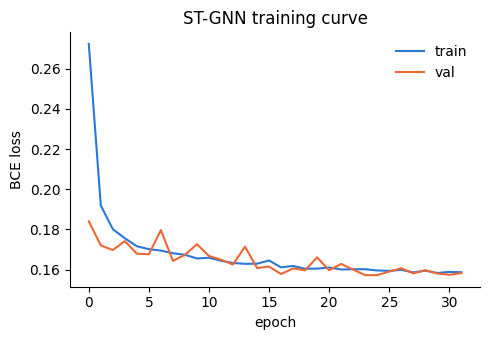

In [12]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(history["train_loss"], color=BLUE, label="train")
ax.plot(history["val_loss"], color=ORANGE, label="val")
ax.set_xlabel("epoch")
ax.set_ylabel("BCE loss")
ax.set_title("ST-GNN training curve")
ax.legend(frameon=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Evaluate the ST-GNN on the held-out test set

ST-GNN classification report (redacted topology + time-weighted edges only):
                  precision    recall  f1-score   support

          benign       0.98      0.95      0.96     50510
lateral_movement       0.91      0.95      0.93     24795

        accuracy                           0.95     75305
       macro avg       0.94      0.95      0.95     75305
    weighted avg       0.95      0.95      0.95     75305

ROC-AUC: 0.9918  PR-AUC: 0.9842


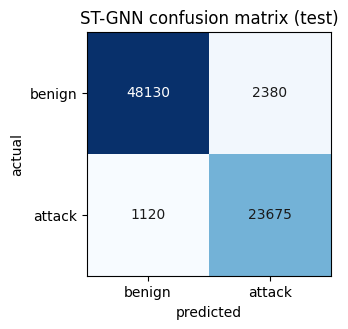

In [13]:
@torch.no_grad()
def predict(loader):
    model.eval()
    probs, ys = [], []
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch)
        probs.append(torch.sigmoid(logits).cpu().numpy())
        ys.append(batch.y.cpu().numpy())
    return np.concatenate(probs), np.concatenate(ys)


def plot_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.imshow(cm, cmap="Blues")
    tick_labels = ["benign", "attack"]
    ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(title)
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > thresh else "#1a1a1a",
            )
    plt.tight_layout()
    plt.show()


test_probs, test_y = predict(test_loader)
test_pred = (test_probs >= 0.5).astype(int)

cm_gnn = confusion_matrix(test_y, test_pred)
print("ST-GNN classification report (redacted topology + time-weighted edges only):")
print(classification_report(test_y, test_pred, target_names=["benign", "lateral_movement"], zero_division=0))
print(f"ROC-AUC: {roc_auc_score(test_y, test_probs):.4f}  PR-AUC: {average_precision_score(test_y, test_probs):.4f}")

plot_confusion(cm_gnn, "ST-GNN confusion matrix (test)")

## 7. Log-dependent baseline — TF-IDF over raw `service:operation` tokens + Logistic Regression

Log-dependent baseline classification report:
                  precision    recall  f1-score   support

          benign       0.91      0.96      0.93     50510
lateral_movement       0.90      0.80      0.85     24795

        accuracy                           0.91     75305
       macro avg       0.91      0.88      0.89     75305
    weighted avg       0.91      0.91      0.91     75305

ROC-AUC: 0.9588  PR-AUC: 0.9086


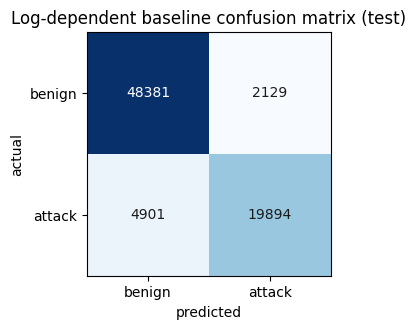

In [14]:
tokens_all = [r["tokens"] for r in records]
vectorizer = TfidfVectorizer(token_pattern=r"[^\s]+", min_df=2)
X_log = vectorizer.fit_transform(tokens_all)

X_train_log, y_train_log = X_log[train_idx], labels[train_idx]
X_test_log, y_test_log = X_log[test_idx], labels[test_idx]

baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
baseline.fit(X_train_log, y_train_log)

base_probs = baseline.predict_proba(X_test_log)[:, 1]
base_pred = (base_probs >= 0.5).astype(int)

cm_base = confusion_matrix(y_test_log, base_pred)
print("Log-dependent baseline classification report:")
print(classification_report(y_test_log, base_pred, target_names=["benign", "lateral_movement"], zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_test_log, base_probs):.4f}  PR-AUC: {average_precision_score(y_test_log, base_probs):.4f}")

plot_confusion(cm_base, "Log-dependent baseline confusion matrix (test)")

## 8. RQ2 comparison

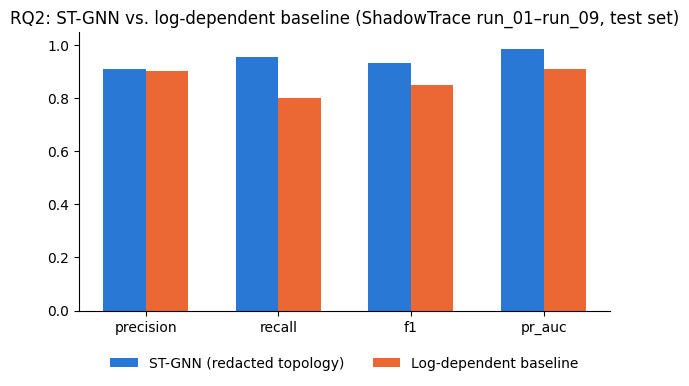

,precision,recall,f1,pr_auc
ST-GNN,0.908655,0.954830,0.931170,0.984209
Log-dependent baseline,0.903328,0.802339,0.849844,0.908577


In [15]:
def summarize(y_true, y_pred, y_prob):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "pr_auc": average_precision_score(y_true, y_prob),
    }


gnn_metrics = summarize(test_y, test_pred, test_probs)
base_metrics = summarize(y_test_log, base_pred, base_probs)

metric_names = ["precision", "recall", "f1", "pr_auc"]
x = np.arange(len(metric_names))
width = 0.32

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - width / 2, [gnn_metrics[m] for m in metric_names], width, label="ST-GNN (redacted topology)", color=BLUE)
ax.bar(x + width / 2, [base_metrics[m] for m in metric_names], width, label="Log-dependent baseline", color=ORANGE)
ax.set_xticks(x); ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.05)
ax.set_title("RQ2: ST-GNN vs. log-dependent baseline (ShadowTrace run_01–run_09, test set)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

comparison_df = pd.DataFrame([gnn_metrics, base_metrics], index=["ST-GNN", "Log-dependent baseline"])
comparison_df

In [16]:
gap = gnn_metrics["f1"] - base_metrics["f1"]
verdict = "comparable to" if abs(gap) <= 0.05 else ("better than" if gap > 0 else "below")
print(
    f"RQ2 (ShadowTrace run_01–run_09, ground-truth labels from ShadowTrace_csv): "
    f"ST-GNN F1={gnn_metrics['f1']:.3f} vs. log-dependent baseline F1={base_metrics['f1']:.3f} "
    f"-> ST-GNN is {verdict} the log-dependent baseline across all nine runs."
)

RQ2 (ShadowTrace run_01–run_09, ground-truth labels from ShadowTrace_csv): ST-GNN F1=0.931 vs. log-dependent baseline F1=0.850 -> ST-GNN is better than the log-dependent baseline across all nine runs.
